In [43]:
from bokeh.io import output_notebook, show
from bokeh.plotting import figure
from bokeh.models import Slider
from bokeh.layouts import column

output_notebook()


# Simple data
x = [1, 2, 3, 4, 5]
y = [2, 5, 3, 7, 6]


# Create plot
p = figure(
    title='Simple Bokeh Dashboard',
    x_axis_label='X',
    y_axis_label='Y',
    width=600,
    height=350
)


# Scatter plot
points = p.scatter(
    x,
    y,
    size=10
)


# Slider
slider = Slider(
    start=5,
    end=30,
    value=10,
    step=1,
    title='Point Size'
)


# Directly connect slider value to point size
slider.js_link(
    'value',
    points.glyph,
    'size'
)


# Dashboard
dashboard = column(
    slider,
    p
)

show(dashboard)

Loading BokehJS ...

In [44]:
from bokeh.io import output_notebook, show, push_notebook
from bokeh.plotting import figure
from bokeh.models import Slider, ColumnDataSource
from bokeh.layouts import column

import random
import time

output_notebook()


# Simple initial data
x = [1, 2, 3, 4, 5]
y = [2, 5, 3, 7, 6]


# Create data source
source = ColumnDataSource(
    data={
        'x': x,
        'y': y
    }
)


# Create plot
p = figure(
    title='Live Bokeh Dashboard',
    x_axis_label='X',
    y_axis_label='Y',
    width=600,
    height=350
)


# Scatter plot
points = p.scatter(
    x='x',
    y='y',
    source=source,
    size=10
)


# Slider
slider = Slider(
    start=5,
    end=30,
    value=10,
    step=1,
    title='Point Size'
)


# Connect slider to scatter point size
slider.js_link(
    'value',
    points.glyph,
    'size'
)


# Dashboard
dashboard = column(
    slider,
    p
)


# Display dashboard
handle = show(
    dashboard,
    notebook_handle=True
)


# Simulate live streaming data
for i in range(6, 100):

    new_y = random.randint(1, 10)

    source.stream({
        'x': [i],
        'y': [new_y]
    })

    push_notebook(handle=handle)

    time.sleep(0.5)

Loading BokehJS ...

In [45]:
from bokeh.io import output_notebook, show
from bokeh.plotting import figure
from bokeh.models import ColumnDataSource, Select, CustomJS
from bokeh.layouts import row

output_notebook()


# Simple data
x = [1, 2, 3, 4, 5]
y = [2, 5, 3, 7, 6]


# Data source
source = ColumnDataSource(
    data={
        'x': x,
        'y': y,
        'selected_y': y
    }
)


# Scatter plot
p = figure(
    title='Interactive Scatter Plot',
    x_axis_label='X',
    y_axis_label='Y',
    width=600,
    height=350
)

p.scatter(
    x='x',
    y='selected_y',
    source=source,
    size=10
)


# Dropdown
dropdown = Select(
    title='Select Y data:',
    value='y',
    options=['x', 'y']
)


# Update plot when dropdown changes
callback = CustomJS(
    args=dict(source=source, dropdown=dropdown),
    code="""
    source.data['selected_y'] = source.data[dropdown.value];
    source.change.emit();
    """
)

dropdown.js_on_change('value', callback)


# Dashboard
dashboard = row(
    dropdown,
    p
)

show(dashboard)

Loading BokehJS ...

In [46]:
import numpy as np

from bokeh.io import output_notebook, show
from bokeh.plotting import figure
from bokeh.models import ColumnDataSource, Select, CustomJS, Div
from bokeh.layouts import row, column

output_notebook()


# Simple data
x = [1, 2, 3, 4, 5]
y = [2, 5, 3, 7, 6]
z = [4, 3, 6, 2, 8]


# Data source
source = ColumnDataSource(
    data={
        'x': x,
        'y': y,
        'z': z,
        'selected_y': y
    }
)


# -----------------------------------------------------
# Basic Statistics
# -----------------------------------------------------

stats_x = Div(
    text=f"""
    <h3>Statistics of X</h3>
    Mean = {np.mean(x):.2f}<br>
    Std = {np.std(x):.2f}<br>
    Min = {np.min(x):.2f}<br>
    Max = {np.max(x):.2f}
    """,
    width=180
)


stats_y = Div(
    text=f"""
    <h3>Statistics of Y</h3>
    Mean = {np.mean(y):.2f}<br>
    Std = {np.std(y):.2f}<br>
    Min = {np.min(y):.2f}<br>
    Max = {np.max(y):.2f}
    """,
    width=180
)


stats_z = Div(
    text=f"""
    <h3>Statistics of Z</h3>
    Mean = {np.mean(z):.2f}<br>
    Std = {np.std(z):.2f}<br>
    Min = {np.min(z):.2f}<br>
    Max = {np.max(z):.2f}
    """,
    width=180
)


# -----------------------------------------------------
# Scatter plot
# -----------------------------------------------------

p = figure(
    title='Interactive Scatter Plot',
    x_axis_label='X',
    y_axis_label='Selected Y data',
    width=600,
    height=350
)

p.scatter(
    x='x',
    y='selected_y',
    source=source,
    size=10
)


# -----------------------------------------------------
# Dropdown
# -----------------------------------------------------

dropdown = Select(
    title='Select Y data:',
    value='y',
    options=['y', 'z']
)


# Update plot when dropdown changes
callback = CustomJS(
    args=dict(source=source, dropdown=dropdown),
    code="""
    source.data['selected_y'] = source.data[dropdown.value];
    source.change.emit();
    """
)

dropdown.js_on_change(
    'value',
    callback
)


# -----------------------------------------------------
# Dashboard
# -----------------------------------------------------

statistics = row(
    stats_x,
    stats_y,
    stats_z
)


dashboard = column(
    statistics,
    
    row(
        dropdown,
        p
    )
)


show(dashboard)

Loading BokehJS ...

In [47]:
#Data Preprocessing
#Data Quality Issues

import pandas as pd
data = pd.read_csv('https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/breast-cancer-wisconsin.data', header=None)

data.columns = ['Sample code', 'Clump Thickness', 'Uniformity of Cell Size', 'Uniformity of Cell Shape',
                'Marginal Adhesion', 'Single Epithelial Cell Size', 'Bare Nuclei', 'Bland Chromatin',
                'Normal Nucleoli', 'Mitoses','Class']

#data = data.drop(['Sample code'],axis=1)
print('Number of instances = %d' % (data.shape[0]))
print('Number of attributes = %d' % (data.shape[1]))
data.head()

Number of instances = 699
Number of attributes = 11


,Sample code,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2


In [48]:
# Missing Values

import numpy as np

data = data.replace('?',np.nan)

# print('Number of instances = %d' % (data.shape[0]))
# print('Number of attributes = %d' % (data.shape[1]))

print(f'Number of instances = {data.shape[0]}')
print(f'Number of attributes = {data.shape[1]}')

print('Number of missing values:')
for col in data.columns:
    print(f'\t{col}: {data[col].isna().sum()}')

Number of instances = 699
Number of attributes = 11
Number of missing values:
	Sample code: 0
	Clump Thickness: 0
	Uniformity of Cell Size: 0
	Uniformity of Cell Shape: 0
	Marginal Adhesion: 0
	Single Epithelial Cell Size: 0
	Bare Nuclei: 16
	Bland Chromatin: 0
	Normal Nucleoli: 0
	Mitoses: 0
	Class: 0


In [51]:
data2 = data['Bare Nuclei']

print('Before replacing missing values:')
print(data2[20:25])

# Convert the column to numeric, coercing errors to NaN
data2 = pd.to_numeric(data2, errors='coerce')

data2 = data2.fillna(data2.median())

print('\nAfter replacing missing values:')
print(data2[20:25])

Before replacing missing values:
20     10
21      7
22      1
23    NaN
24      1
Name: Bare Nuclei, dtype: object

After replacing missing values:
20    10.0
21     7.0
22     1.0
23     1.0
24     1.0
Name: Bare Nuclei, dtype: float64


In [52]:
## Drop NA
print(f'Number of rows in original data = {data.shape[0]}')

data2 = data.dropna()
print(f'Number of rows after discarding missing values = {data2.shape[0]}')

Number of rows in original data = 699
Number of rows after discarding missing values = 683


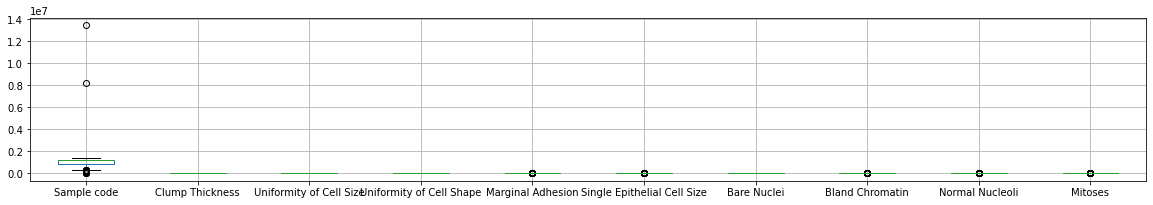

In [53]:
import matplotlib.pyplot as plt

data2 = data.drop(['Class'], axis=1)
data2['Bare Nuclei'] = pd.to_numeric(data2['Bare Nuclei'])

data2.boxplot(figsize=(20,3))
plt.show()

In [54]:
Z = (data2-data2.mean())/data2.std()
#Z[20:25]

print('Number of rows before discarding outliers = %d' % Z.shape[0])

# Ensure Z is a DataFrame
if isinstance(Z, pd.Series):
    Z = Z.to_frame()

# Keep rows where all columns are between -3 and 3
Z2 = Z[(Z > -3).all(axis=1) & (Z <= 3).all(axis=1)]

print('Number of rows after discarding outliers = %d' % Z2.shape[0])


Number of rows before discarding outliers = 699
Number of rows after discarding outliers = 630


In [55]:
# 4.1.3 Duplicate Data

dups = data.duplicated()
print('Number of duplicate rows = %d' % (dups.sum()))
data.loc[[11,28]]

Number of duplicate rows = 8


,Sample code,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses,Class
11,1036172,2,1,1,1,2,1,2,1,1,2
28,1067444,2,1,1,1,2,1,2,1,1,2


In [56]:
print(f'Number of rows before discarding duplicates = {data.shape[0]}')
data2 = data.drop_duplicates()
print(f'Number of rows after discarding duplicates = {data2.shape[0]}')

Number of rows before discarding duplicates = 699
Number of rows after discarding duplicates = 691


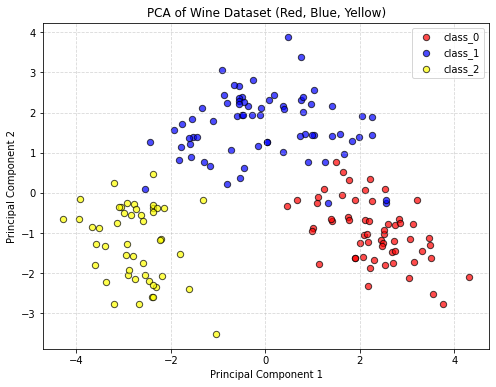

In [57]:
#PCA

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Load and Standardize
wine = load_wine()
X = wine.data
y = wine.target
target_names = wine.target_names

X_scaled = StandardScaler().fit_transform(X)

# PCA having 2 Components ---
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Create DataFrame ---
df = pd.DataFrame(X_pca, columns=['PC1','PC2'])
df['class'] = y

# Plot PC1 vs PC2 with Red, Blue, Yellow ---
plt.figure(figsize=(8,6))
colors = ['red','blue','yellow']

for class_value, color, label in zip(range(3), colors, target_names):
    subset = df[df['class']==class_value]
    plt.scatter(subset.PC1, subset.PC2, 
                c=color, label=label, 
                s=40, alpha=0.7, edgecolors='k')

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA of Wine Dataset (Red, Blue, Yellow)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


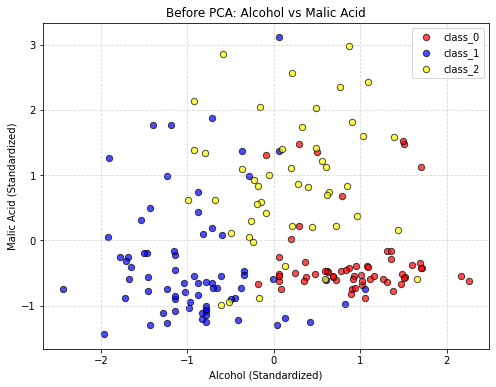

In [58]:
# =====================================================
# Create DataFrame for Original Features
# =====================================================

df_original = pd.DataFrame(
    X_scaled,
    columns=wine.feature_names
)

df_original['class'] = y


# =====================================================
# Plot Before PCA
# =====================================================

colors = ['red', 'blue', 'yellow']

plt.figure(figsize=(8, 6))


for class_value, color, label in zip(
    range(3),
    colors,
    target_names
):

    subset = df_original[
        df_original['class'] == class_value
    ]

    plt.scatter(
        subset['alcohol'],
        subset['malic_acid'],
        c=color,
        label=label,
        s=40,
        alpha=0.7,
        edgecolors='k'
    )


plt.xlabel('Alcohol (Standardized)')
plt.ylabel('Malic Acid (Standardized)')

plt.title('Before PCA: Alcohol vs Malic Acid')

plt.legend()

plt.grid(
    True,
    linestyle='--',
    alpha=0.5
)

plt.show()

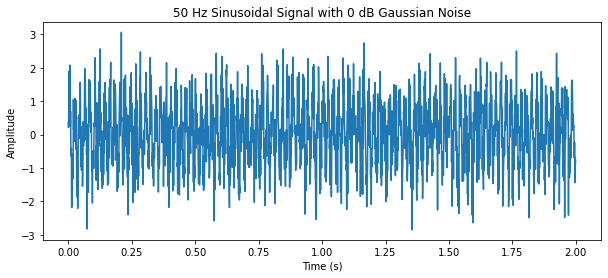

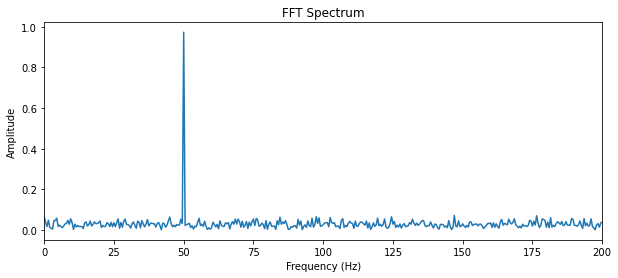

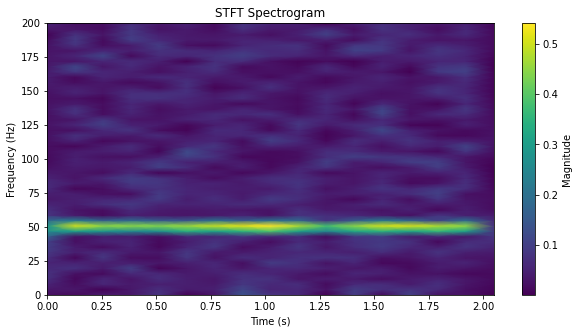

In [41]:
# Data Transformation

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import stft


# =====================================================
# Generate Sinusoidal Signal
# =====================================================

Fs = 1000              # Sampling frequency
T = 2                  # Duration in seconds
t = np.arange(0, T, 1/Fs)

f0 = 50                # Sinusoidal frequency
#f0 = 50*(1+0.5*t)

signal = np.sin(2 * np.pi * f0 * t)

# =====================================================
# Add Gaussian Noise at 0 dB SNR
# =====================================================

np.random.seed(42)

signal_power = np.mean(signal**2)

noise = np.random.randn(len(signal))

noise = noise * np.sqrt(
    signal_power / np.mean(noise**2)
)

# Signal x(t)
noisy_signal = signal + noise 


# =====================================================
# Plot Signal
# =====================================================

plt.figure(figsize=(10, 4))

plt.plot(t, noisy_signal)

plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title('50 Hz Sinusoidal Signal with 0 dB Gaussian Noise')

plt.show()


# =====================================================
# FFT
# =====================================================

N = len(noisy_signal)

fft_values = np.fft.fft(noisy_signal)

freq = np.fft.fftfreq(
    N,
    1/Fs
)


# Plot only positive frequencies
plt.figure(figsize=(10, 4))

plt.plot(
    freq[:N//2],
    2/N * np.abs(fft_values[:N//2])
)

plt.xlabel('Frequency (Hz)')
plt.ylabel('Amplitude')
plt.title('FFT Spectrum')

plt.xlim(0, 200)

plt.show()


# =====================================================
# STFT
# =====================================================

f, t_stft, Zxx = stft(
    noisy_signal,
    fs=Fs,
    nperseg=256
)


# =====================================================
# STFT Spectrogram
# =====================================================

plt.figure(figsize=(10, 5))

plt.pcolormesh(
    t_stft,
    f,
    np.abs(Zxx),
    shading='gouraud'
)

plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')
plt.title('STFT Spectrogram')

plt.ylim(0, 200)

plt.colorbar(
    label='Magnitude'
)

plt.show()